# Qismet: revised performance experiment

**Real hardware result:** the revised sampler achieved **81.651% expected best-of-32 test accuracy**, versus **81.478%** for uniform random search, a **+0.172 percentage-point** improvement at the same 32-raw-proposal budget. This is one model initialization and one finite measurement batch per depth; it is not a speedup claim.

The revised ideal QAOA sampler improved expected retrained test accuracy over uniform random pruning on **all five fresh initializations**. Mean gain per accepted proposal: **+0.771 percentage points**. Mean expected best-of-32 gain: **+0.233 percentage points**. These are ideal-simulation results; hardware results are stated separately below.

## What changed and why

The dataset remains Fashion-MNIST and the model remains 784→16→10. We fit the QUBO on **35 masks at the desired size**, rather than mixing multiple network sizes. Regularization is selected by cross-validation on those masks. Another 35 masks audit prediction fidelity. Only half the hidden neurons survive, reducing parameters from **12,730 to 6,370**.

The new circuit starts with four Bell pairs and uses paired RXX/RYY rotations on a ring. These XY mixers preserve the number of retained groups in an ideal circuit. Removing the large size penalty lets the cost phases represent quality differences directly. This is the constrained alternating-operator approach described by [Hadfield et al.](https://arxiv.org/abs/1709.03489).

Three QAOA layers use six angles, optimized on a CPU simulator with three fixed starts. Hardware executes frozen angles; it does not perform the earlier online SPSA loop. Both the earlier and revised methods are hybrids with classical preparation costs.

## Independent ideal-simulation follow-up

Fresh initializations: 101, 202, 303, 404, 505. Each network, surrogate, circuit and selected mask is frozen before test evaluation. The same Fashion-MNIST split is reused. This is an exploratory follow-up; fresh seeds check initialization dependence, not a new dataset.

| Metric | Uniform feasible masks | Revised ideal QAOA |
|---|---:|---:|
| Expected test accuracy per proposal | 80.130% | 80.901% |
| Expected test accuracy, best of 32 | 81.155% | 81.389% |
| Chance of top-10% QUBO mask | 10.00% | 53.52% |

Dense mean accuracy: **82.50%**. The revised ideal best-of-32 subnetworks retain half the parameters with an average accuracy drop of **1.11 percentage points**.

The paired 95% t interval across five initializations is **[0.569, 0.974] pp** for the one-proposal gain and **[0.012, 0.455] pp** for best-of-32. These small-sample intervals condition on this dataset and ideal probabilities. They do not include dataset uncertainty, hardware noise or all researcher choices.

Expected metrics integrate the frozen sampling distribution against the actual retrained performance of all 70 valid masks. Best-of-32 selects by the QUBO, not by true test performance. This avoids presenting one lucky quantum draw against one unlucky random draw. It does not remove the simulator's optimization cost from the experiment.

![Fresh initializations](fresh_seed_performance.png)

## Is the QUBO more accurate?

The revised surrogate's mean held-out R² is **0.450** and mean absolute validation-loss error is **0.0132** on the five fresh initializations. On the original five development seeds, fixed-size fitting improved mean R² from **−3.465 to 0.333**, and mean absolute error from **0.0357 to 0.0139**, using the same original audit masks. Prediction is useful but still imperfect.

![Surrogate and sampling](surrogate_and_sampling.png)

## Actual hardware follow-up

Four real follow-up jobs ran on **ibm_fez**, consuming **12 QPU seconds**. All completed jobs across the project report **32 seconds** of QPU usage. The earlier queued Kingston attempt was cancelled before any QAOA result because of queue latency; its metrics currently report zero charge with pending usage status. Its 60-second reservation remains conservatively accounted. Both the partial attempt and all four Fez comparisons are preserved.

The chosen depth is **2**, selected using mean QUBO score before test evaluation. Its feasible fraction is **38.6%**. Among feasible outputs it samples top-10% masks **27.6%** of the time; counting every raw shot this is **10.6%**. Uniform feasible sampling is 10%.

Expected test accuracy per accepted hardware proposal is **80.59%**, versus **80.16%** for uniform feasible masks. Expected best-of-32 accuracy, including the raw-shot acceptance process, is **81.65%**, versus **81.48%** for random search. Probability of no feasible mask in 32 shots: **1.6e-07**.

The single frozen 32-shot selection achieved **81.81%** test accuracy. The corresponding seeded random selection achieved **81.29%**. Classical exact QUBO search found the same selected mask (state 60) and therefore matches its 81.81% test accuracy. Single draws are not the primary evidence of distribution quality.

The one-layer circuit also showed a small positive best-of-32 gain. The three-layer circuit did not improve that metric, illustrating the tradeoff between ideal expressiveness and device noise. The two-layer circuit accepts only **38.6%** of raw shots. Conditional sampling gains must be reported alongside this rejection overhead.

All four depths, job IDs, shot counts, validation loss and test accuracy are in `hardware/depth_comparison.csv`. Hardware uncertainty and drift are not captured by the initialization intervals below.

A multinomial bootstrap of these finite-shot batches, repeating QUBO-based depth selection, gives a sampling-only 95% interval of **[0.140, 0.202] percentage points** for the expected best-of-32 gain. It excludes device drift, dataset uncertainty and earlier experiment-design choices. It is not evidence of universal advantage.

## What the success does and does not establish

The ideal follow-up demonstrates better proposal quality and a small positive best-of-32 accuracy gain against the specified uniform-random baseline. It also improves held-out surrogate fidelity. All five fresh initialization results are reported.

Classical exact QUBO search remains cheap for 70 masks and is a stronger optimization reference than random sampling. This experiment does **not** demonstrate quantum speedup, superiority over all classical methods, or quantum advantage. A cost-aware comparison must include label generation, regression, simulator angle optimization, circuit preparation, QPU usage, queue latency and final retraining. Repeatedly evaluating candidates through a learned surrogate is a benefit available to classical optimizers too.

## Files

- `Revised_Walkthrough.ipynb` and `Results.html`: executed explanatory notebook and readable export.
- `fresh_seed_summary.csv`: all five independent ideal results.
- `fresh_seeds/seed_*/selection_frozen.json`: choices frozen before test evaluation.
- `hardware/depth_comparison.csv`: all real circuits and their quality metrics, when complete.
- `constrained_experiment.py`: actual revised circuit and IBM execution code.


In [1]:
from pathlib import Path
import inspect,json
import pandas as pd
from IPython.display import display,Image
import constrained_experiment as experiment
BASE=Path('.').resolve()
experiment.verify()
print(inspect.getsource(experiment.build))
display(pd.read_csv(BASE/'fresh_seed_summary.csv')[['seed','audit_r2','qaoa_expected_test_accuracy','random_expected_test_accuracy','qaoa_best32_expected_test_accuracy','random_best32_expected_test_accuracy']])


PASS: all 15 actual Qiskit circuits match the independent subspace simulator; 1.0547118733938987e-15
def build(seed=11,layers=3):
    a=np.load(HERE/f'pilot_p{max(1,layers)}_seed_{seed}.npz')
    qc=QuantumCircuit(8,name=f'constrained_p{layers}')
    # Four Bell pairs: one excitation per pair, exactly four overall.
    for i in range(0,8,2): qc.h(i); qc.x(i+1); qc.cx(i,i+1)
    if layers==0: return qc
    linear=a['linear']; b=np.zeros((8,8)); b[np.triu_indices(8,1)]=a['pairs']
    h=-linear/2-(b+b.T).sum(1)/4; J=b/4
    theta=a['theta']; scale=float(a['scale'])
    for l in range(layers):
        for i in range(8): qc.rz(2*theta[l]*h[i]/scale,i)
        for i in range(8):
            for j in range(i+1,8): qc.rzz(2*theta[l]*J[i,j]/scale,i,j)
        # Each adjacent XY rotation swaps |01> and |10> without changing count.
        for i,j in EDGES:
            qc.rxx(theta[layers+l],i,j); qc.ryy(theta[layers+l],i,j)
    return qc



,seed,audit_r2,qaoa_expected_test_accuracy,random_expected_test_accuracy,qaoa_best32_expected_test_accuracy,random_best32_expected_test_accuracy
0,101,0.195492,0.799063,0.791893,0.801568,0.801242
1,202,0.346869,0.806282,0.796447,0.811888,0.808418
2,303,0.424895,0.814580,0.806284,0.818200,0.815811
3,404,0.633084,0.815849,0.810476,0.817500,0.816644
4,505,0.649954,0.809296,0.801399,0.820272,0.815648


## Actual circuit
The initial Bell pairs and every XY mixer preserve four retained groups in the ideal circuit. Real-device errors can violate this constraint, so hardware acceptance must be measured.

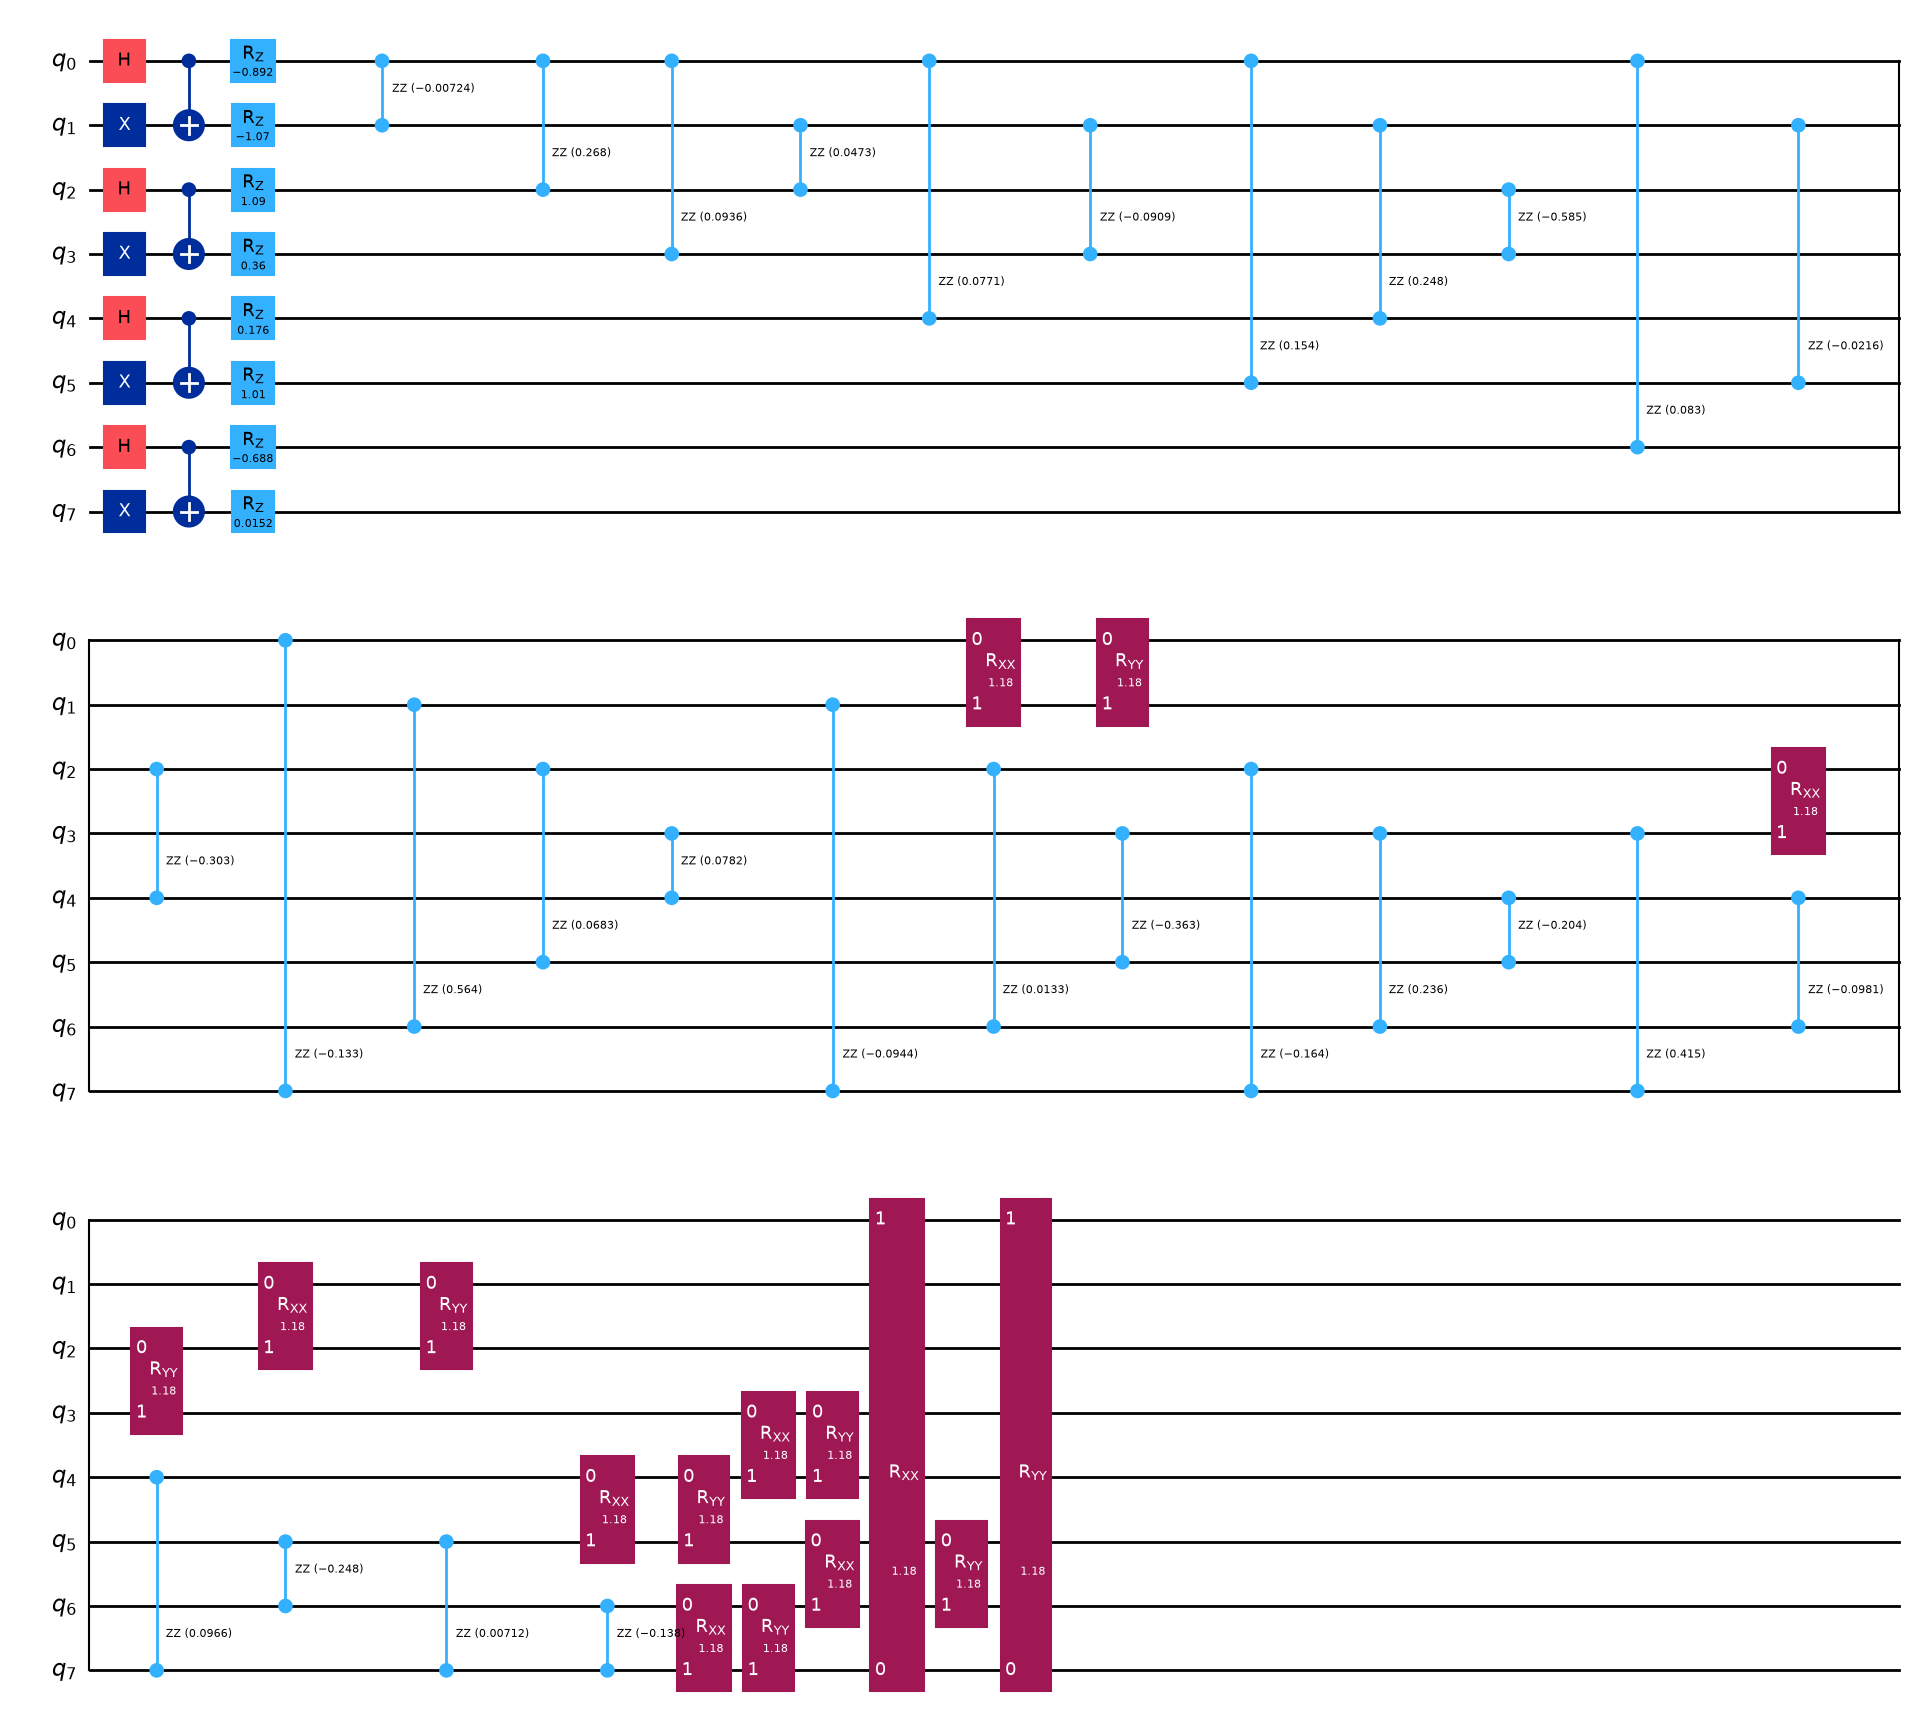

In [2]:
import matplotlib.pyplot as plt
qc=experiment.build(seed=11,layers=1)
fig=qc.draw(output='mpl',fold=28)
fig.savefig(BASE/'constrained_circuit.png',dpi=130,bbox_inches='tight')
display(fig); plt.close(fig)


## Saved hardware evidence

,layers,shots,feasible_fraction,top10_probability_raw,top10_probability_conditional,predicted_loss_conditional,validation_loss_conditional,best32_validation_loss,no_feasible_in32_probability,qpu_seconds,job_id,expected_test_accuracy,best32_expected_test_accuracy,expected_validation_loss_se
0,0,4096,0.901367,0.000732,0.000813,0.576174,0.578273,0.557687,6.437027e-33,3.0,dbmj0ld8mdtc73d81tp0,0.799739,0.807187,0.000208
1,1,4096,0.540039,0.117188,0.216998,0.564823,0.564581,0.539473,1.610907e-11,3.0,dbmj0t9kbkrc73cpj5sg,0.805379,0.816564,0.000346
2,2,4096,0.386230,0.106445,0.275601,0.563383,0.564634,0.540481,1.645017e-07,3.0,dbmj1758mdtc73d81ujg,0.805932,0.816506,0.000439
3,3,4096,0.316650,0.059570,0.188126,0.566538,0.567188,0.544932,5.111807e-06,3.0,dbmj1hl8mdtc73d81vbg,0.804568,0.814458,0.000459


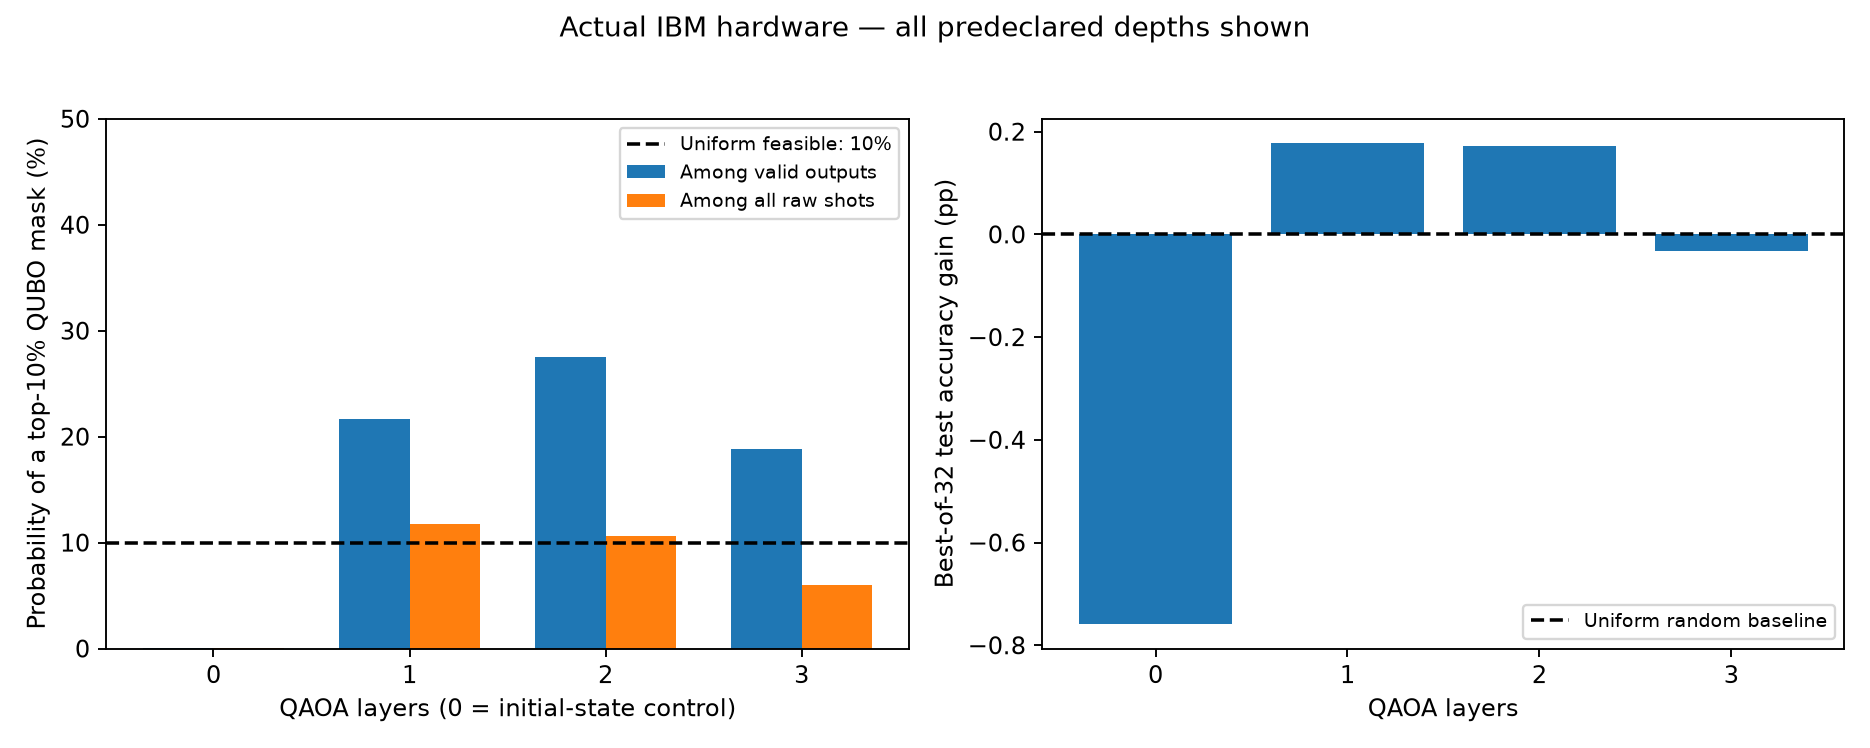

In [3]:
path=BASE/'hardware'/'depth_comparison.csv'
if path.exists():
    display(pd.read_csv(path))
    display(Image(filename=str(BASE/'hardware_performance.png')))
else:
    print('Hardware follow-up pending; the simulation results above are not hardware results.')
